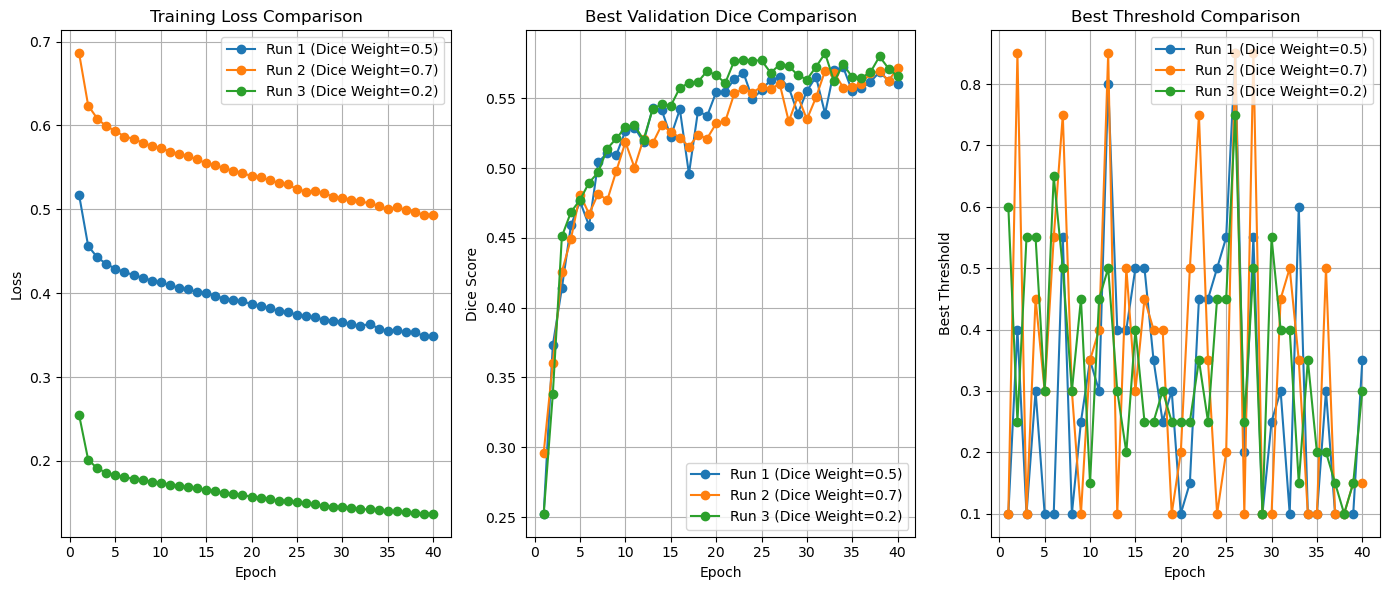

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os


metrics_files = {
    "Run 1 (Dice Weight=0.5)": "Output/model01_dicebce0.5_loss/training_validation_metrics.csv",
    "Run 2 (Dice Weight=0.7)": "Output/model01_dicebce0.7_loss/training_validation_metrics.csv",
    "Run 3 (Dice Weight=0.2)": "Output/model01_dicebce0.2_loss/training_validation_metrics.csv"
}

fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Best Threshold Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Best Threshold")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))


# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)
    
    # Plot Best Threshold
    ax3.plot(epoch_summary["epoch"], epoch_summary["threshold"], marker='o', label=label)

  
# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()



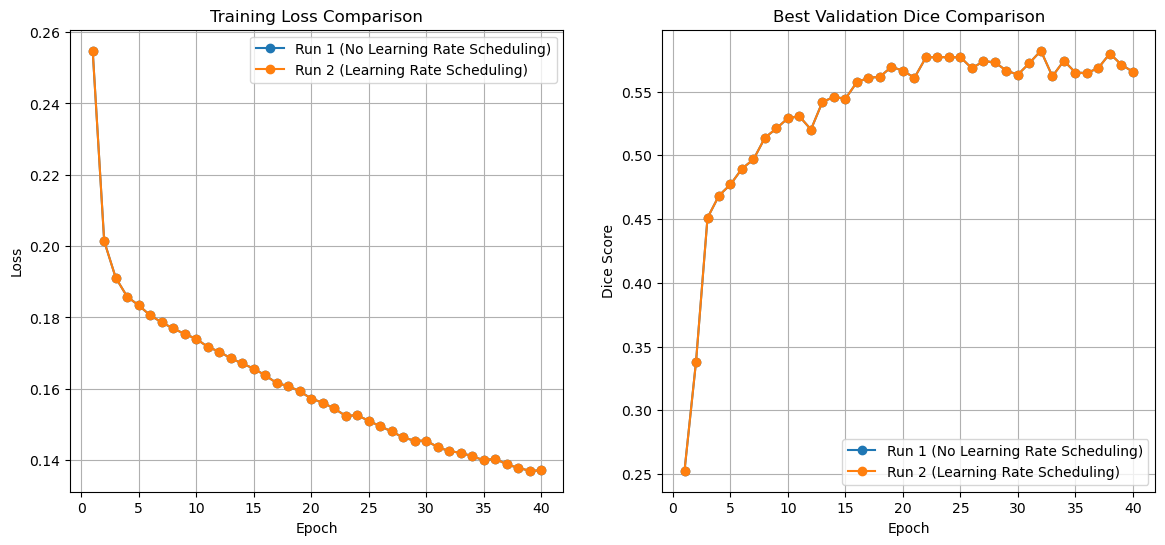

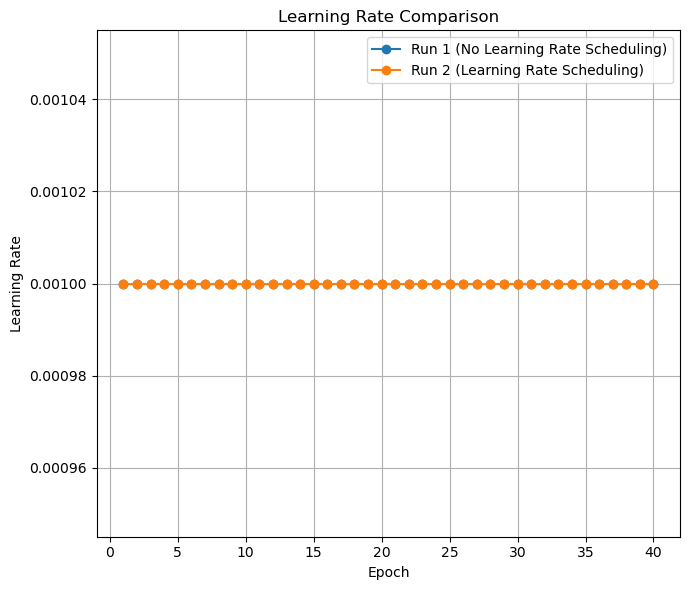

In [3]:
metrics_files = {
    "Run 1 (No Learning Rate Scheduling)": "Output/model01_dicebce0.2_loss/training_validation_metrics.csv",
    "Run 2 (Learning Rate Scheduling)": "Output/model01_dicebce0.2_loss_scheduler/training_validation_metrics.csv",
}    

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Learning Rate Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Learning Rate")
ax3.grid(True)  
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max")
    ).reset_index().head(40)

    if "Run 1" in label or "learning_rate" not in epoch_summary.columns:
        epoch_summary["learning_rate"] = 1e-3
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

    # Plot Learning Rate
    ax3.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()

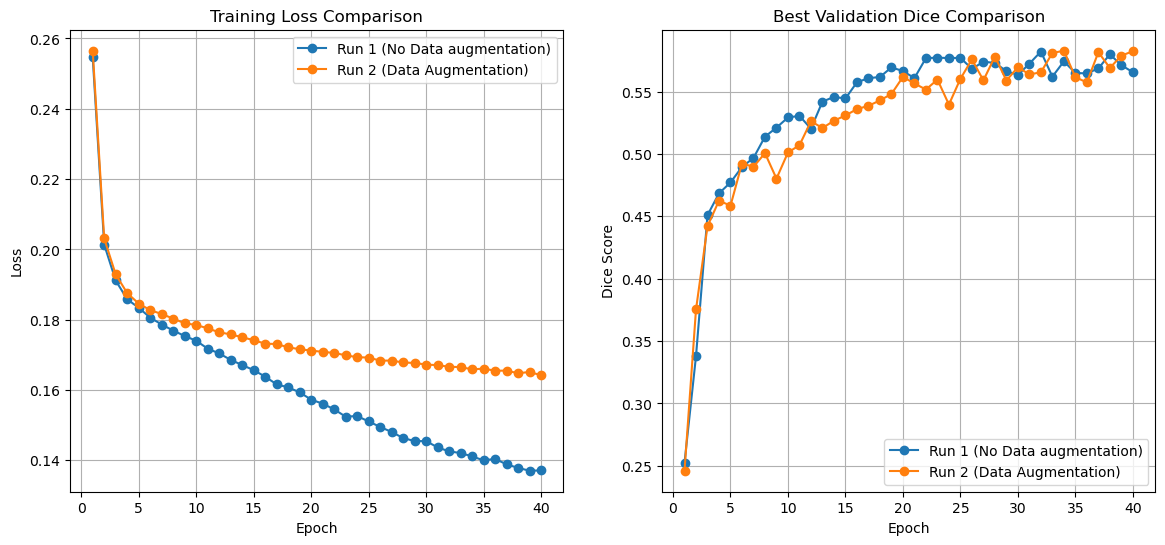

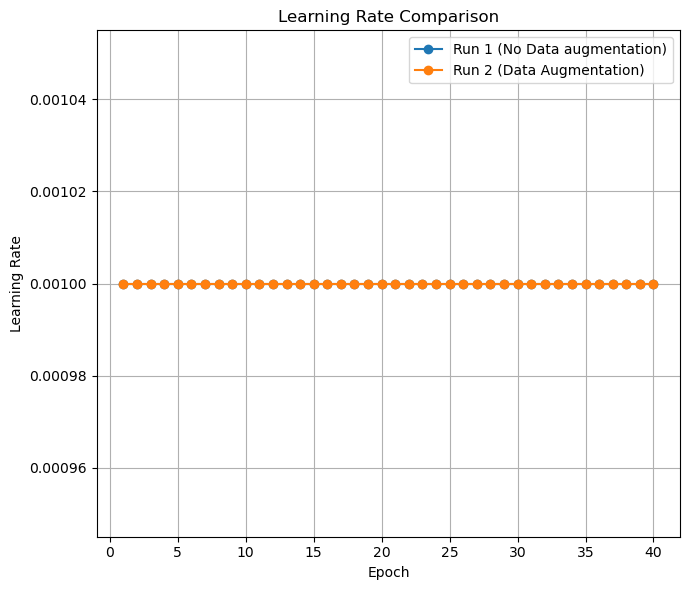

In [4]:
metrics_files = {
    "Run 1 (No Data augmentation)": "Output/model01_dicebce0.2_loss_scheduler/training_validation_metrics.csv",
    "Run 2 (Data Augmentation)": "Output/model01_dicebce0.2_loss_scheduler_augmented/training_validation_metrics.csv"
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Learning Rate Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Learning Rate")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max"),
        learning_rate=("learning_rate", "first")
    ).reset_index().head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

    # Plot Learning Rate
    ax3.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()



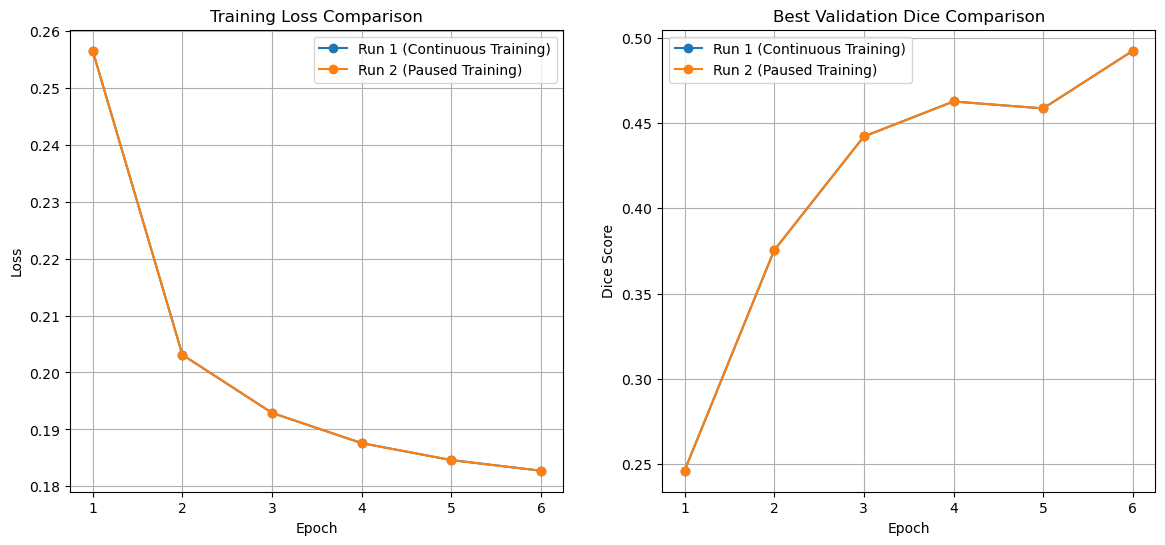

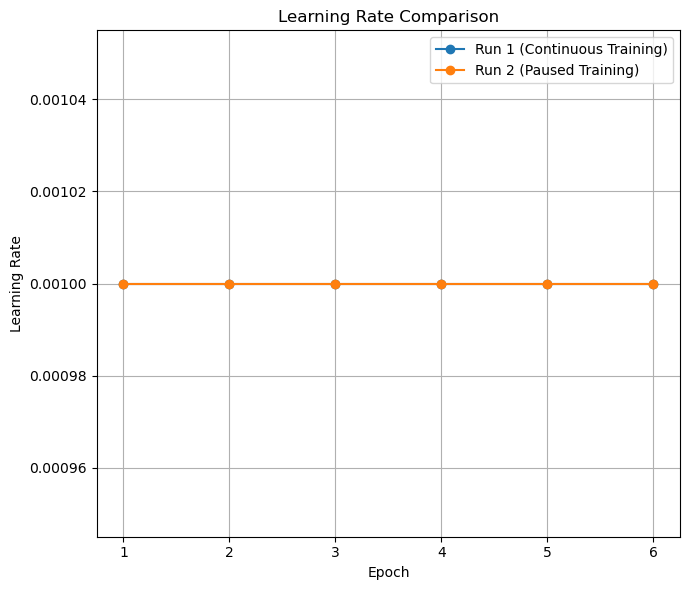

In [5]:
metrics_files = {
    "Run 1 (Continuous Training)": "Output/model01_continuity_test_full/training_validation_metrics.csv",
    "Run 2 (Paused Training)": "Output/model01_continuity_test_continued_max_6_from_3/training_validation_metrics.csv"
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Learning Rate Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Learning Rate")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max"),
        learning_rate=("learning_rate", "first")
    ).reset_index().head(6)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

    # Plot Learning Rate
    ax3.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()



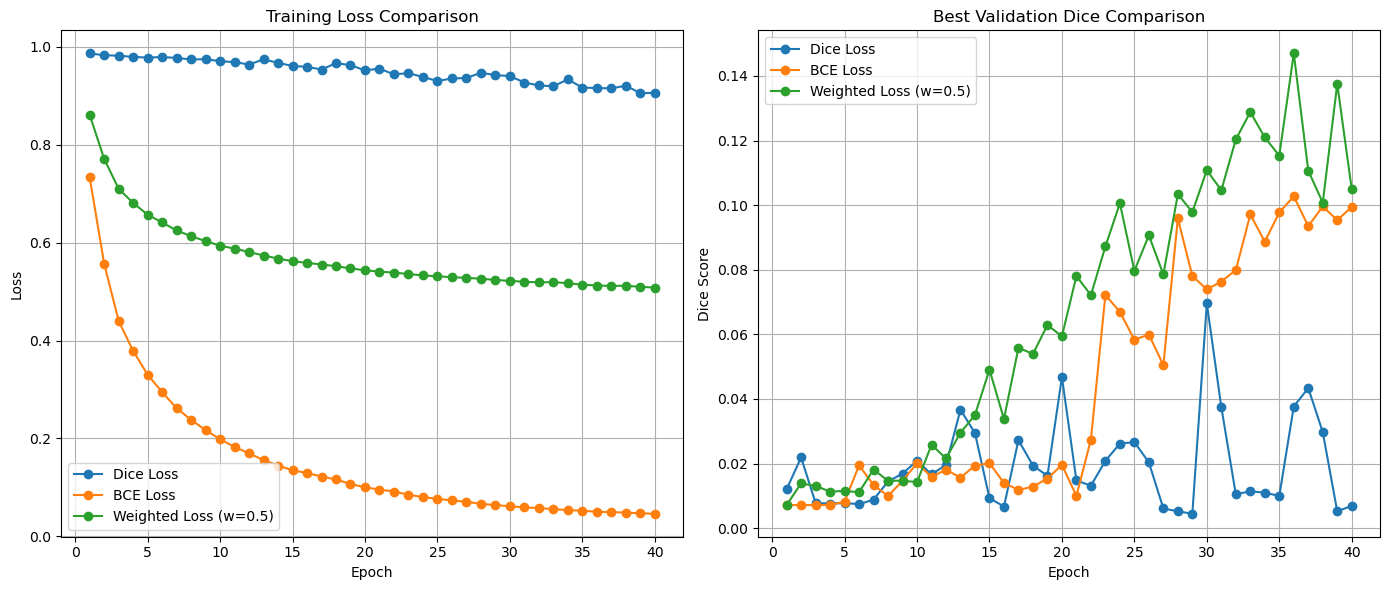

In [6]:
metrics_files = {
    "Dice Loss": "Output/model01_overfit_dice_loss/training_validation_metrics.csv",
    "BCE Loss": "Output/model01_overfit_bce_loss/training_validation_metrics.csv",
    "Weighted Loss (w=0.5)": "Output/model01_overfit_dicebce0.5_loss/training_validation_metrics.csv"
}

fig1, (ax1,ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))



# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
plt.tight_layout()
plt.show()



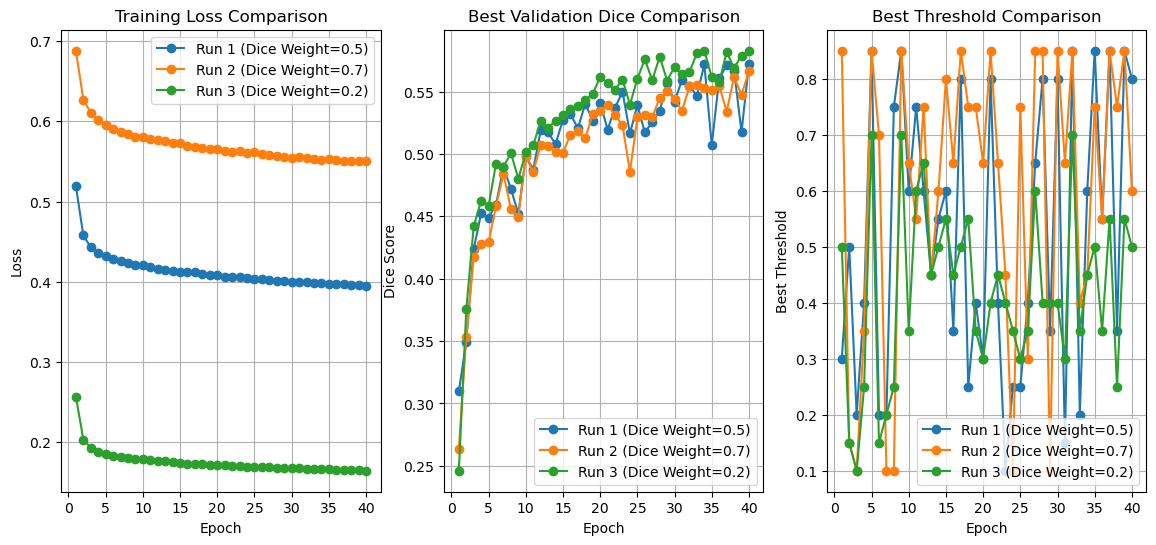

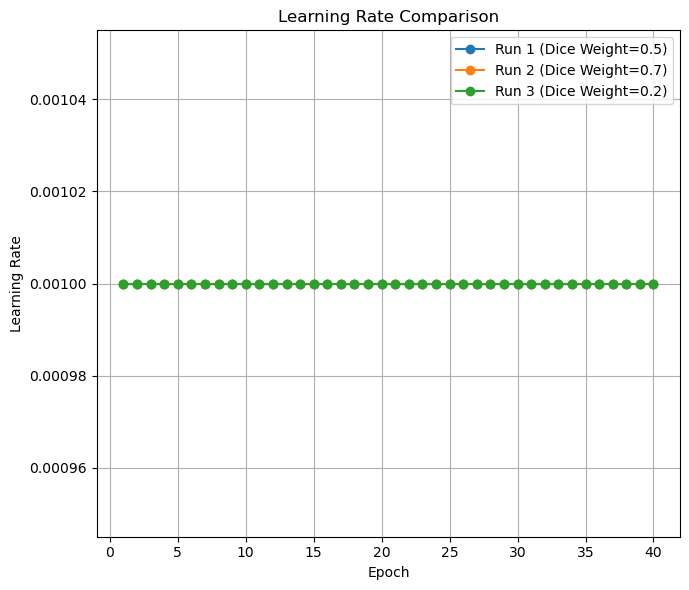

In [7]:
metrics_files = {
    "Run 1 (Dice Weight=0.5)": "Output/model01_dicebce0.5_loss_scheduler_augmented/training_validation_metrics.csv",
    "Run 2 (Dice Weight=0.7)": "Output/model01_dicebce0.7_loss_scheduler_augmented/training_validation_metrics.csv",
    "Run 3 (Dice Weight=0.2)": "Output/model01_dicebce0.2_loss_scheduler_augmented/training_validation_metrics.csv"
}

fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))
fig2, ax4 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Best Threshold Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Best Threshold")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Learning Rate Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Learning Rate")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)
    
    # Plot Best Threshold
    ax3.plot(epoch_summary["epoch"], epoch_summary["threshold"], marker='o', label=label)

    # Plot Learning Rate
    ax4.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
plt.tight_layout()
plt.show()



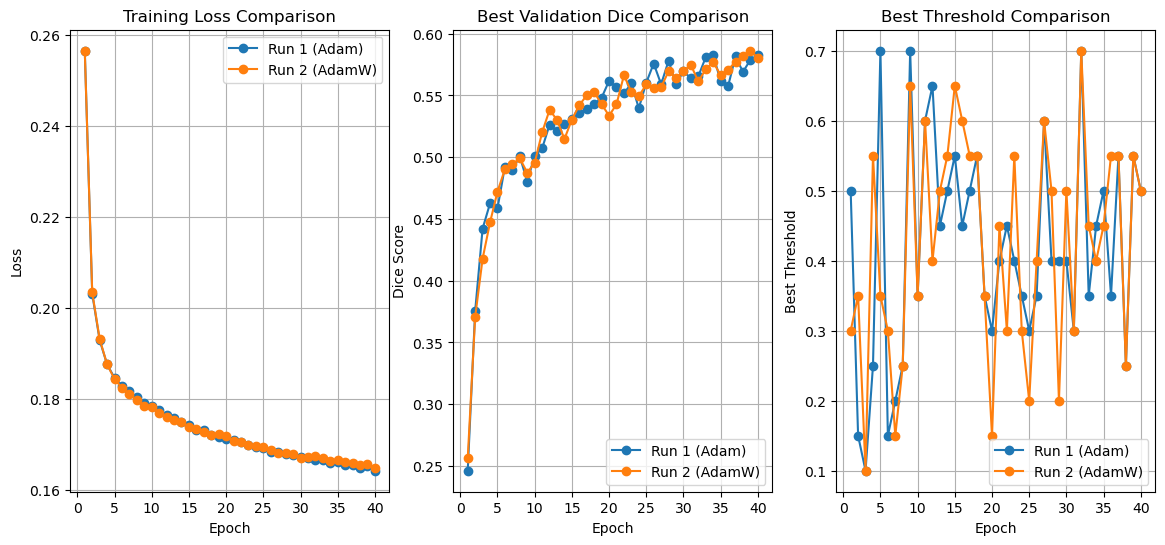

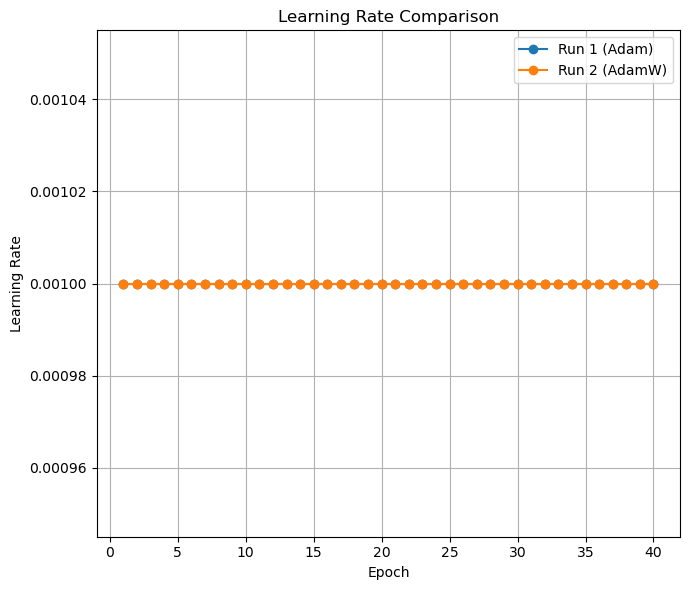

In [8]:
metrics_files = {
    "Run 1 (Adam)": "Output/model01_dicebce0.2_loss_scheduler_augmented/training_validation_metrics.csv",
    "Run 2 (AdamW)": "Output/model01_dicebce0.2_loss_scheduler_augmented_adamw/training_validation_metrics.csv",
}

fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))
fig2, ax4 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Best Threshold Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Best Threshold")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Learning Rate Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Learning Rate")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)
    
    # Plot Best Threshold
    ax3.plot(epoch_summary["epoch"], epoch_summary["threshold"], marker='o', label=label)

    # Plot Learning Rate
    ax4.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
plt.tight_layout()
plt.show()



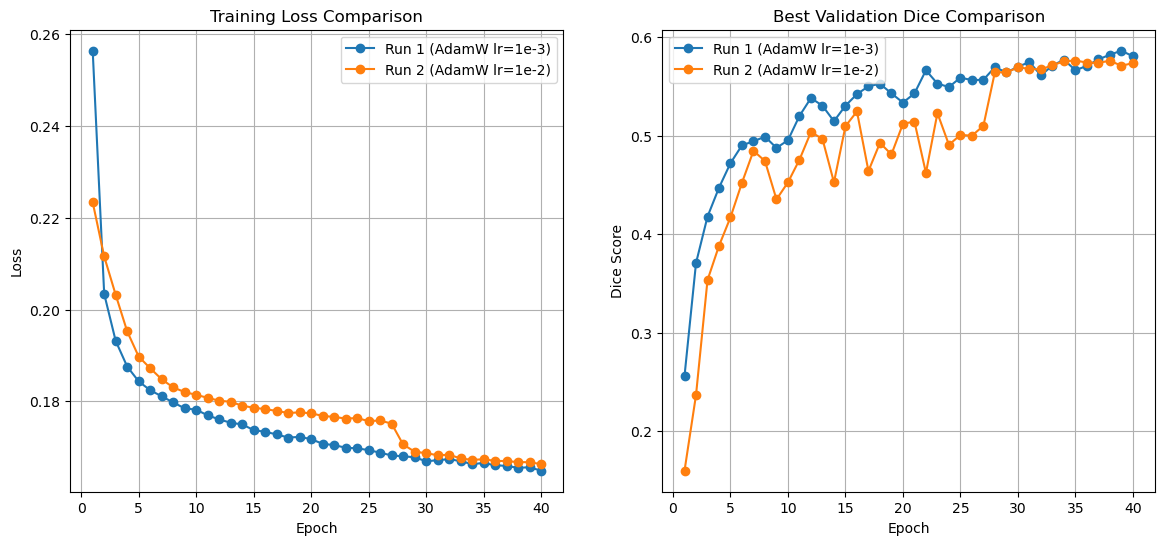

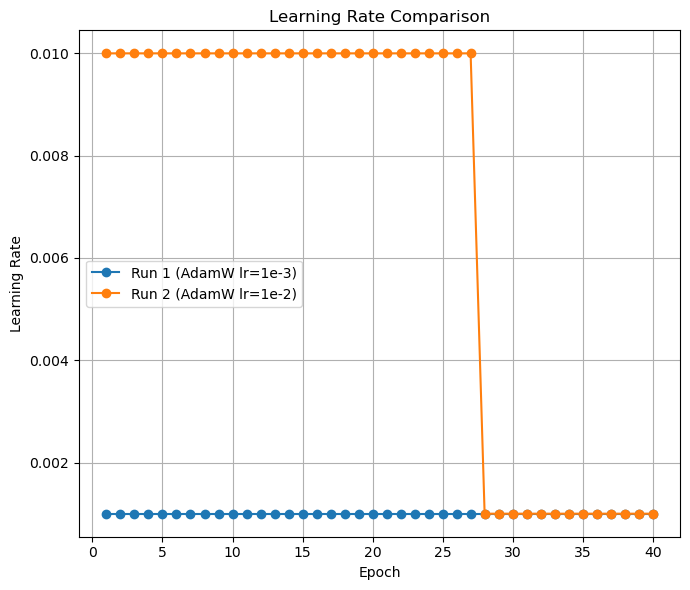

In [9]:
metrics_files = {
    "Run 1 (AdamW lr=1e-3)": "Output/model01_dicebce0.2_loss_scheduler_augmented_adamw/training_validation_metrics.csv",
    "Run 2 (AdamW lr=1e-2)": "Output/model01_dicebce0.2_loss_scheduler_augmented_adamw_lr/training_validation_metrics.csv",
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax4 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

# ax3.set_title("Best Threshold Comparison")
# ax3.set_xlabel("Epoch")
# ax3.set_ylabel("Best Threshold")
# ax3.grid(True)
# ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Learning Rate Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Learning Rate")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)
    
    # Plot Best Threshold
    #ax3.plot(epoch_summary["epoch"], epoch_summary["threshold"], marker='o', label=label)

    # Plot Learning Rate
    ax4.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
#ax3.legend()
ax4.legend()
plt.tight_layout()
plt.show()



In [10]:
results = []

for folder_name in os.listdir('Output'):
    
    metrics_file = os.path.join('Output', folder_name, "training_validation_metrics.csv")
        
    if os.path.exists(metrics_file):
            try:
                df = pd.read_csv(metrics_file)
                
                if 'dice' in df.columns:
                    max_epoch = df['epoch'].max()
                    best_idx = df['dice'].idxmax()
                    best_row = df.loc[best_idx]
                    results.append({
                        'Folder': folder_name,
                        'Best Dice': best_row['dice'],
                        'Epoch': f"{int(best_row['epoch'])}/{max_epoch}",
                        'Threshold': best_row['threshold']

                    })
            except Exception as e:
                print(f"Error reading {metrics_file}: {e}")


results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='Best Dice', ascending=False).reset_index(drop=True)
print(results_df.to_string())

                                                                                    Folder  Best Dice    Epoch  Threshold
0                                                                  model01_new_scheduler_2   0.656429  131/150       0.35
1                                                                            model02_0.001   0.655701  110/120       0.35
2                                                                            model03_0.001   0.655423  119/120       0.35
3    model01_new_dicebce0.001_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full   0.654296  119/120       0.35
4                                                                    model01_new_scheduler   0.654001  117/120       0.35
5     model01_new_dicebce0.01_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full   0.652639  111/120       0.35
6   model01_new_dicebce0.0001_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full   0.652032  120/120       0.35
7                       

/home/dinis/.conda/envs/AE4353/lib/python3.11/site-packages/albumentations/core/validation.py:132: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


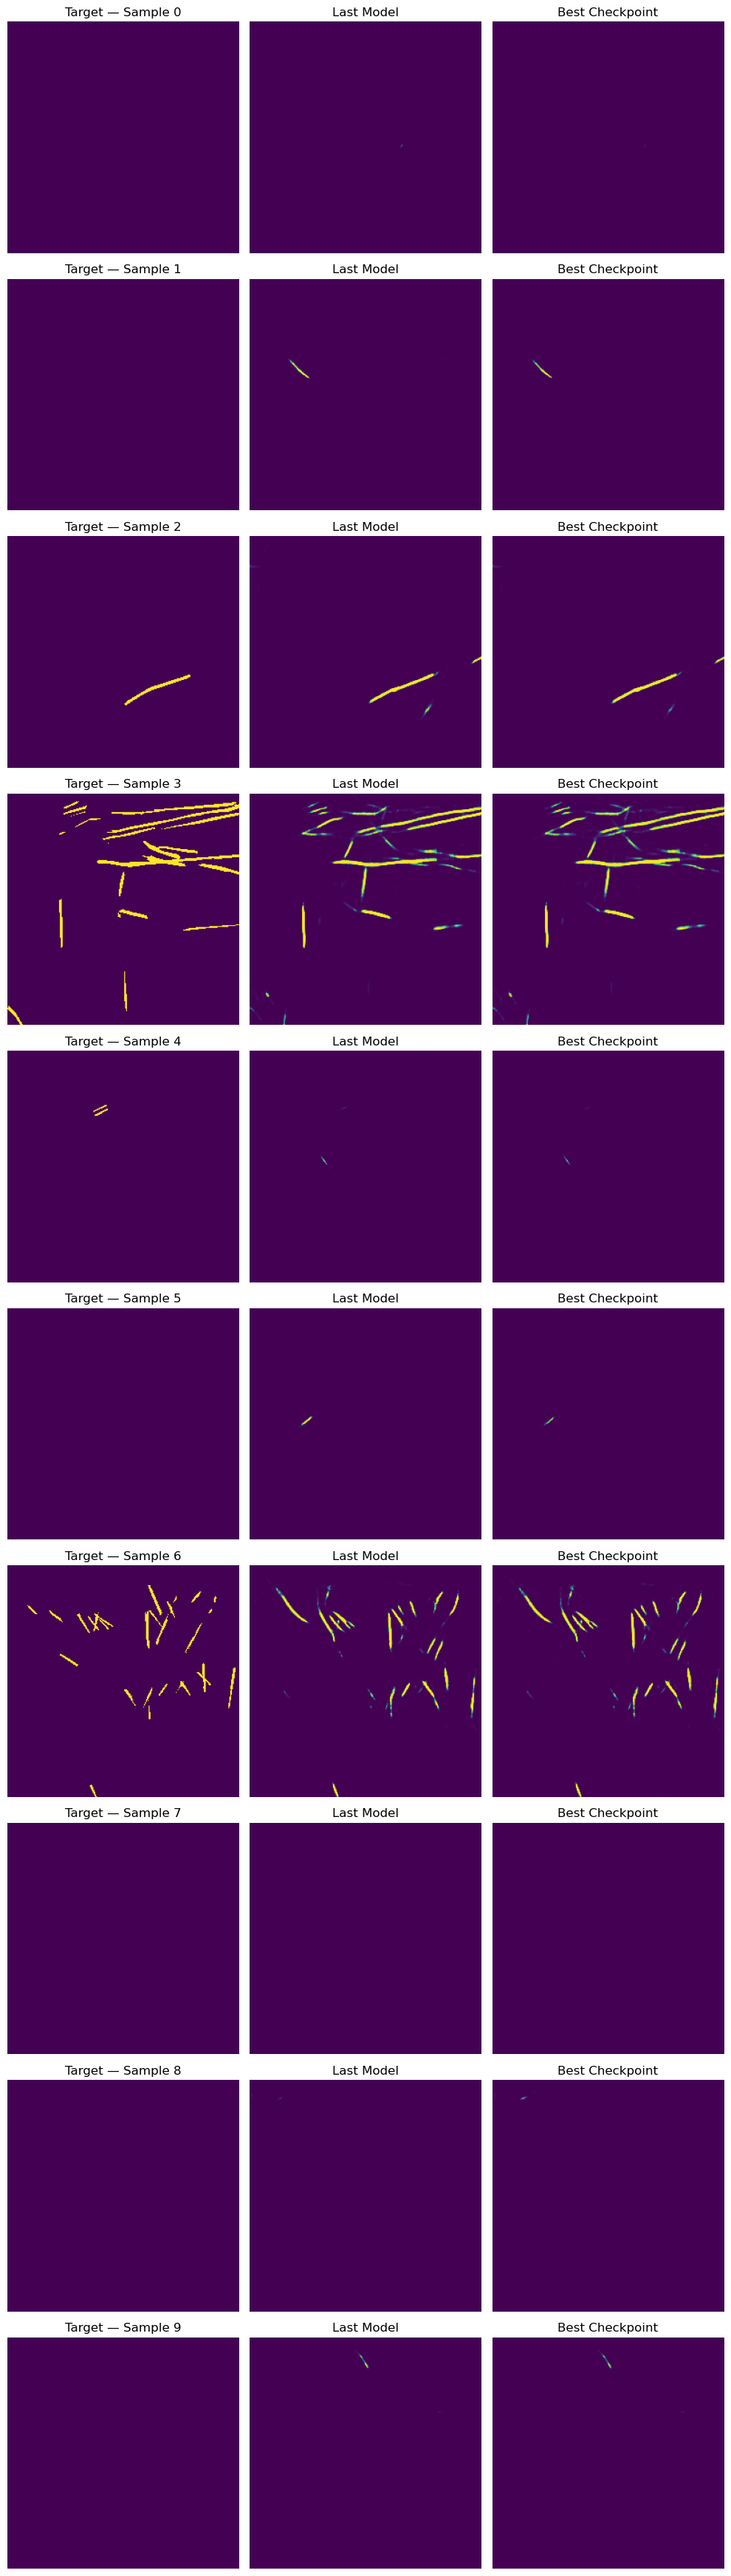

In [11]:
import Models
import torch
import glob
import h5py
import random
import numpy as np
from src.dataset import Dataset
from torch.utils.data import DataLoader
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATASET_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Data/ae4353-2026"

OUTPUT_BASE_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Output"
SESSION_ID = "model01_dicebce0.2_loss_scheduler_augmented_adamw_more_epochs"
model = Models.model01.Contrail_CNN()

OUTPUT_PATH = os.path.join(OUTPUT_BASE_PATH, SESSION_ID)
train_files = sorted(glob.glob(f"{DATASET_PATH}/train_*.h5"))
VAL_SPLIT = 0.2
BATCH_SIZE = 8
NUM_WORKERS = 4
SEED = 2006
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)                     # seeds the GPU as well
torch.backends.cudnn.benchmark = False      # the same algorithms on every run
torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


total_train_images = sum([len(h5py.File(f, 'r')['bands']) for f in train_files])

val_size = int(total_train_images * VAL_SPLIT)
train_size = total_train_images - val_size

# Shuffle the indices of the training images
indices = torch.randperm(total_train_images, generator=torch.Generator().manual_seed(SEED)).tolist()
val_indices = indices[:val_size]
train_indices = indices[val_size:]

full_train_dataset = Dataset(train_files, is_test=False, do_augmentation=True, seed=SEED)
full_val_dataset = Dataset(train_files, is_test=False, do_augmentation=False, seed=SEED)
train_dataset = torch.utils.data.Subset(full_train_dataset, train_indices)
val_dataset = torch.utils.data.Subset(full_val_dataset, val_indices)

g = torch.Generator()
g.manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=g,
    shuffle=True
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    shuffle=True
)


best_checkpoint_path = os.path.join(OUTPUT_PATH, "best_checkpoint.pth")
last_checkpoint_path = os.path.join(OUTPUT_PATH, "last_checkpoint.pth")
best_checkpoint = torch.load(best_checkpoint_path, map_location=device, weights_only=False)
last_checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)


# Comparison of Last and Best Model Predictions
model.load_state_dict(last_checkpoint['model_state_dict'])

# Starting with the last model
model.eval()
model.to(device)

selected_indices = list(range(min(10, len(val_dataset))))
last_preds_samples = []
sample_images = []
sample_targets = []

with torch.no_grad():
    for idx in selected_indices:
        img, target_mask = val_dataset[idx]
        sample_images.append(img)
        sample_targets.append(target_mask.squeeze().numpy())
        
        pred = model(img.unsqueeze(0).to(device))
        last_preds_samples.append(torch.sigmoid(pred).squeeze().cpu().numpy())

# Best Model
model.load_state_dict(best_checkpoint['model_state_dict'])
model.eval() # Good practice to explicitly set eval again

best_preds_samples = []

with torch.no_grad():
    for img in sample_images:
        pred = model(img.unsqueeze(0).to(device))
        best_preds_samples.append(torch.sigmoid(pred).squeeze().cpu().numpy())

# Plot
n_samples = len(sample_images)
fig, axes = plt.subplots(n_samples, 3, figsize=(10, 3.5 * n_samples))
axes = np.atleast_2d(axes)

for row in range(n_samples):
    # Ground Truth
    axes[row, 0].imshow(sample_targets[row], cmap="viridis")
    axes[row, 0].set_title(f"Target — Sample {selected_indices[row]}")
    axes[row, 0].axis("off")

    # Last Model (Heatmap)
    axes[row, 1].imshow(last_preds_samples[row], cmap="viridis", vmin=0, vmax=1)
    axes[row, 1].set_title("Last Model")
    axes[row, 1].axis("off")

    # Best Model (Heatmap)
    axes[row, 2].imshow(best_preds_samples[row], cmap="viridis", vmin=0, vmax=1)
    axes[row, 2].set_title("Best Checkpoint")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, "prediction_examples_comparison.png"))
plt.show()
plt.close()

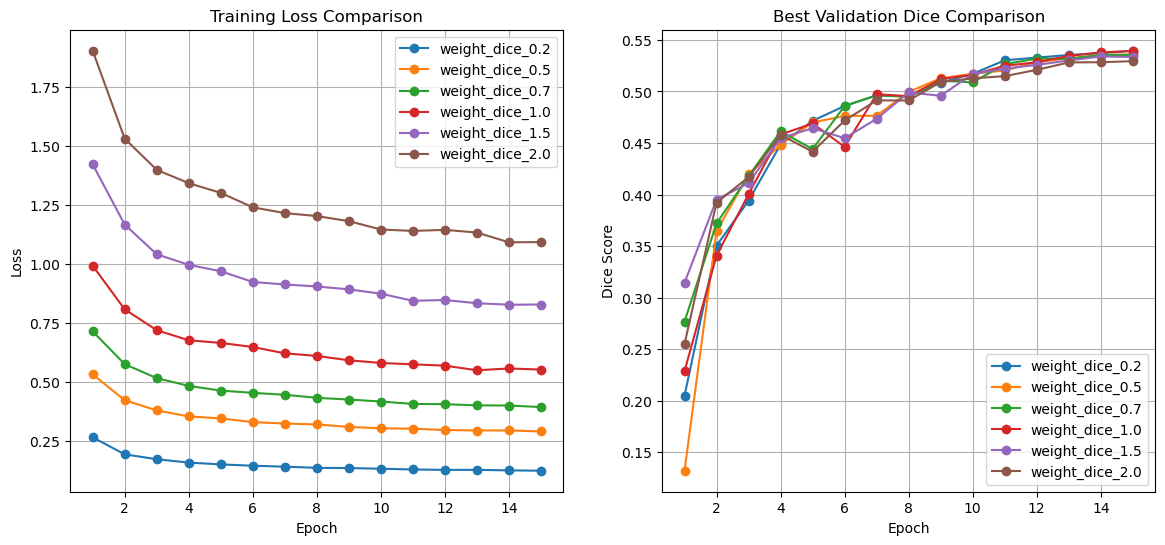

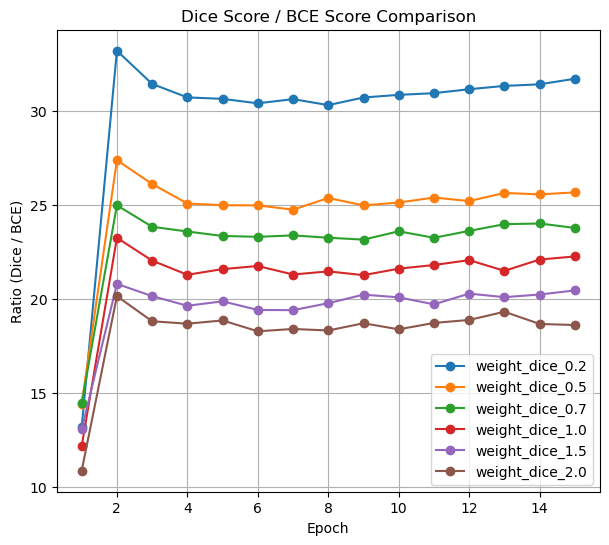

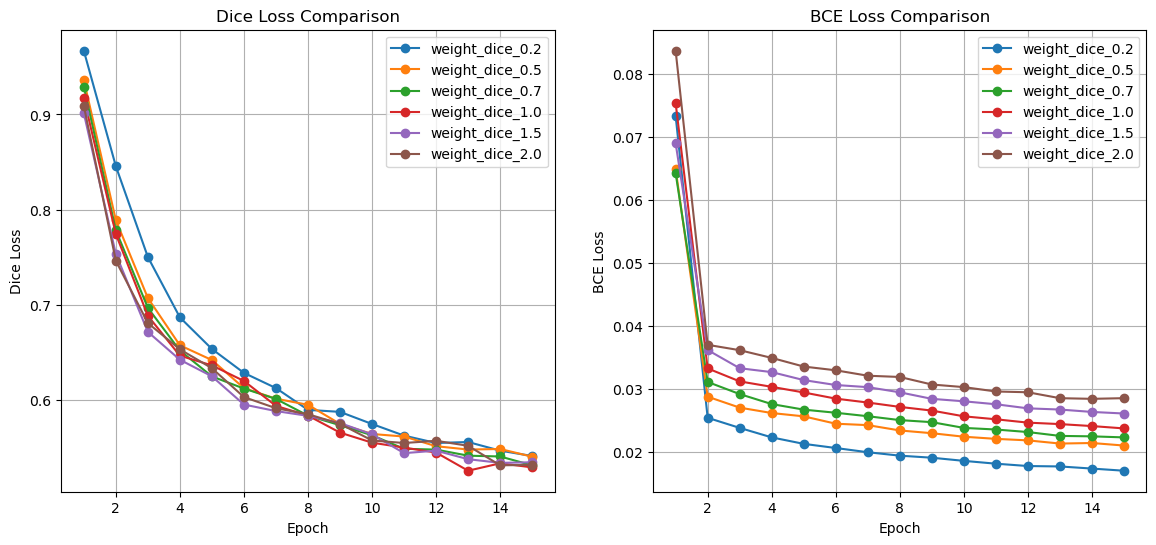

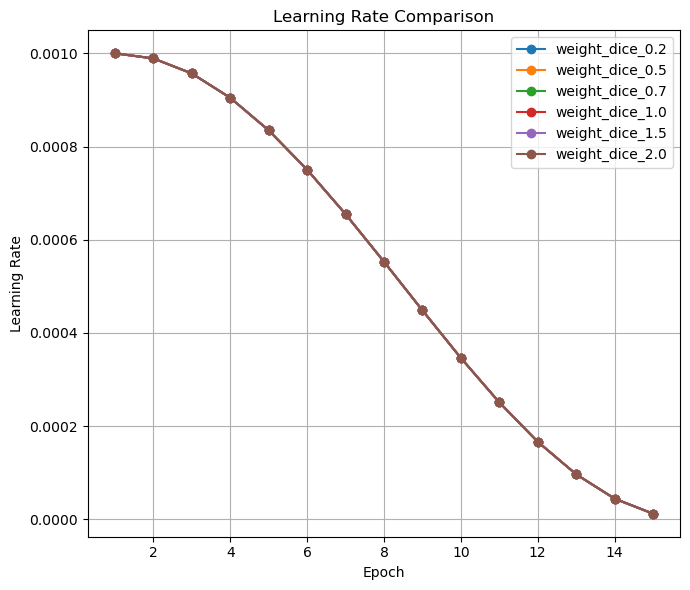

            Run  Initial Loss  Second Loss  Last Loss  Last - Initial  Last - Second  Last - Second Last
weight_dice_2.0      1.902073     1.529942   1.092580       -0.809493      -0.437362            0.000827
weight_dice_1.5      1.421158     1.166460   0.828352       -0.592806      -0.338108            0.000663
weight_dice_1.0      0.992763     0.807776   0.553235       -0.439527      -0.254541           -0.004645
weight_dice_0.7      0.714728     0.576029   0.394489       -0.320239      -0.181540           -0.006653
weight_dice_0.5      0.533051     0.423363   0.291397       -0.241654      -0.131965           -0.004444
weight_dice_0.2      0.266763     0.194604   0.125342       -0.141421      -0.069262           -0.001473


In [12]:
metrics_files = {
    "weight_dice_0.2": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.2_new_loss_cos_scheduler_more_augmented_adamw_more_epochs", "training_validation_metrics.csv"),
    "weight_dice_0.5": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.5_new_loss_cos_scheduler_more_augmented_adamw_more_epochs", "training_validation_metrics.csv"),
    "weight_dice_0.7": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.7_new_loss_cos_scheduler_more_augmented_adamw_more_epochs", "training_validation_metrics.csv"),
    "weight_dice_1.0": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce1.0_new_loss_cos_scheduler_more_augmented_adamw_more_epochs", "training_validation_metrics.csv"),
    "weight_dice_1.5": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce1.5_new_loss_cos_scheduler_more_augmented_adamw_more_epochs", "training_validation_metrics.csv"),
    "weight_dice_2.0": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce2.0_new_loss_cos_scheduler_more_augmented_adamw_more_epochs", "training_validation_metrics.csv")
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))
fig3, (ax4, ax5) = plt.subplots(1, 2, figsize=(14, 6))
fig4, ax6 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Dice Score / BCE Score Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Ratio (Dice / BCE)")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Dice Loss Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Dice Loss")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

ax5.set_title("BCE Loss Comparison")
ax5.set_xlabel("Epoch")
ax5.set_ylabel("BCE Loss")
ax5.grid(True)
ax5.xaxis.set_major_locator(MaxNLocator(integer=True))

ax6.set_title("Learning Rate Comparison")
ax6.set_xlabel("Epoch")
ax6.set_ylabel("Learning Rate")
ax6.grid(True)
ax6.xaxis.set_major_locator(MaxNLocator(integer=True))


# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx]
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)

    # Plot Dice/BCE Ratio
    ratio = epoch_summary["avg_loss_dice"] / epoch_summary["avg_loss_bce"]
    ax3.plot(epoch_summary["epoch"], ratio, marker='o', label=label)

    # Plot Dice Loss
    ax4.plot(epoch_summary["epoch"], epoch_summary["avg_loss_dice"], marker='o', label=label)
    ax5.plot(epoch_summary["epoch"], epoch_summary["avg_loss_bce"], marker='o', label=label)
    
    # Plot Learning Rate
    ax6.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
ax5.legend()
ax6.legend()
plt.tight_layout()
plt.show()

loss_summary = []

for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue

    df = pd.read_csv(filepath)

    # Keep one training loss per epoch (same value for all thresholds)
    epoch_loss = df.groupby("epoch", as_index=False)["avg_train_loss"].first()

    if len(epoch_loss) == 0:
        continue

    initial_loss = float(epoch_loss["avg_train_loss"].iloc[0])
    second_loss = float(epoch_loss["avg_train_loss"].iloc[1]) if len(epoch_loss) > 1 else initial_loss
    second_last_loss = float(epoch_loss["avg_train_loss"].iloc[-2]) if len(epoch_loss) > 1 else initial_loss
    last_loss = float(epoch_loss["avg_train_loss"].iloc[-1])

    initial_dice = float()

    loss_summary.append({
        "Run": label,
        "Initial Loss": initial_loss,
        "Second Loss": second_loss,
        "Last Loss": last_loss,
        "Last - Initial": last_loss - initial_loss,
        "Last - Second": last_loss - second_loss,
        "Last - Second Last": last_loss - second_last_loss
    })

loss_summary_df = pd.DataFrame(loss_summary)
loss_summary_df = loss_summary_df.sort_values(
    by=["Last - Initial", "Last - Second", "Last - Second Last"],
    ascending=[True, True, True]
).reset_index(drop=True)

print(loss_summary_df.to_string(index=False))

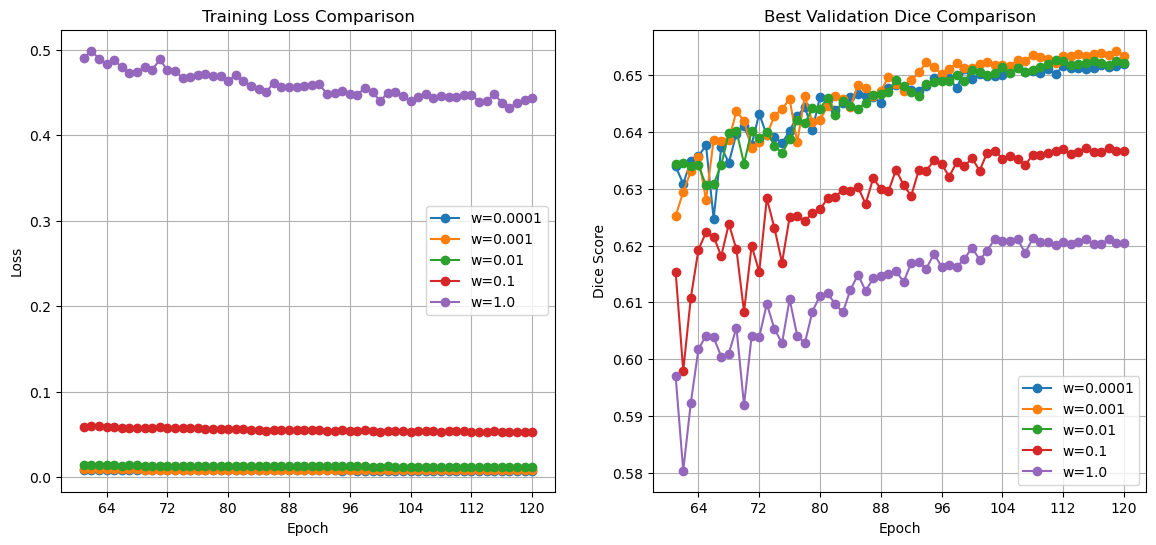

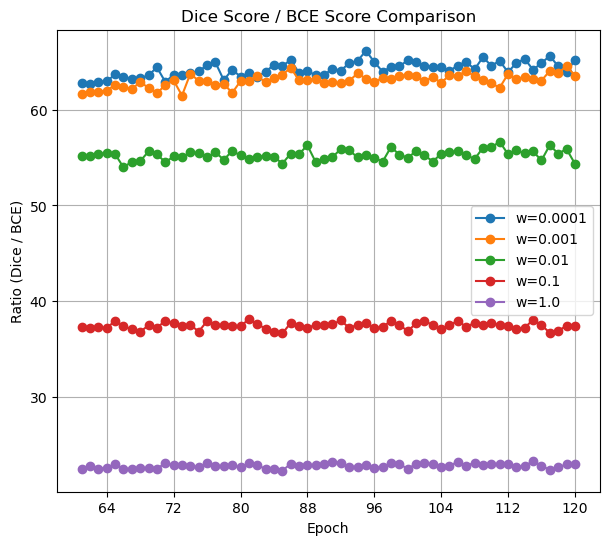

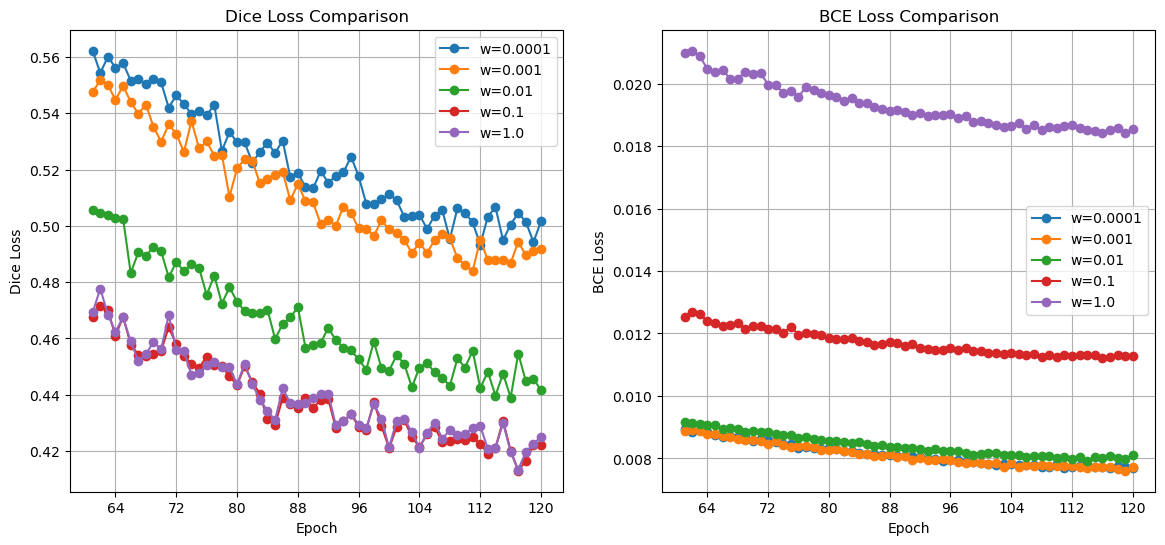

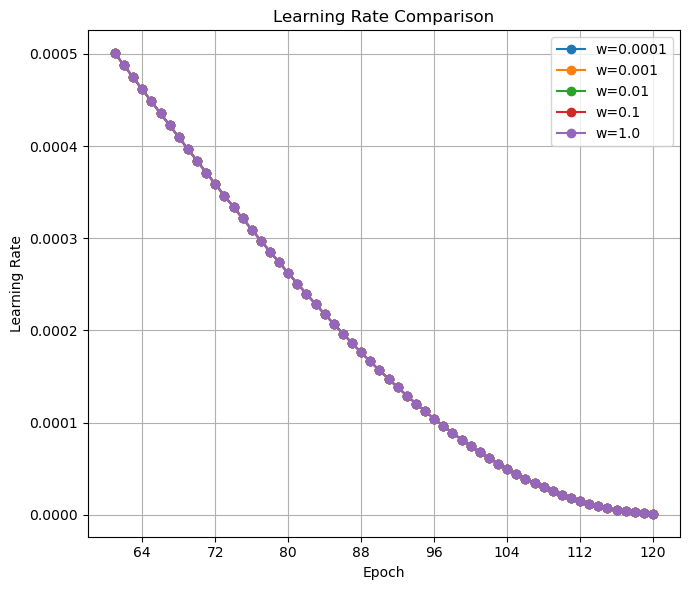

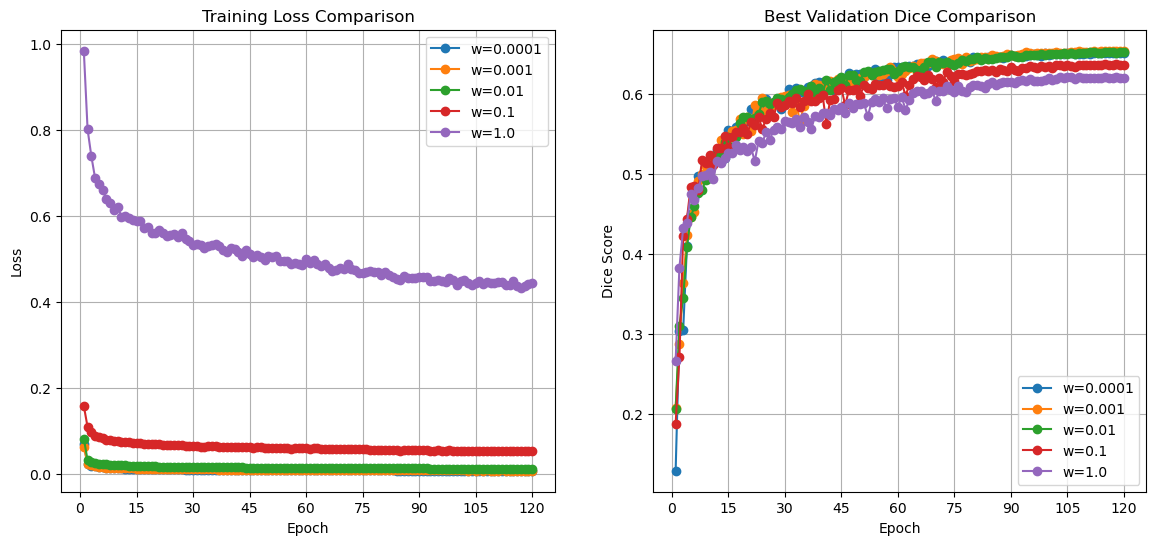

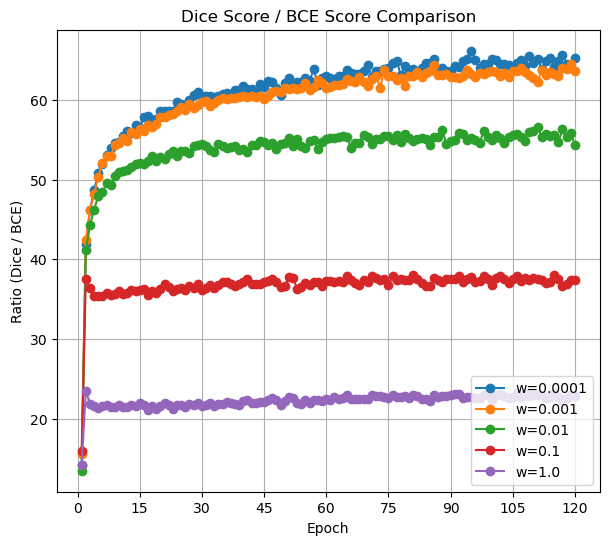

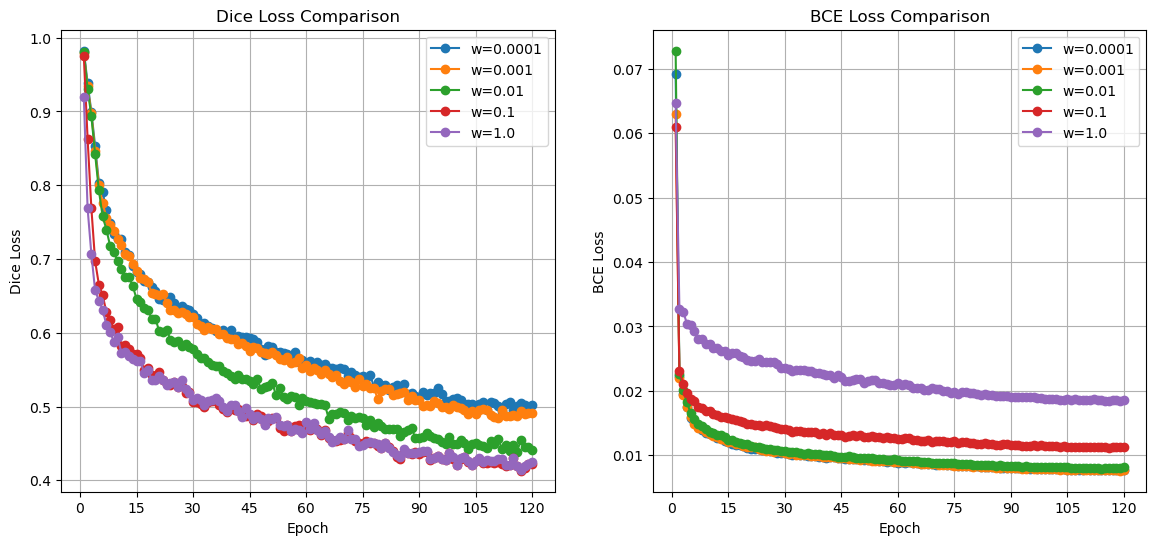

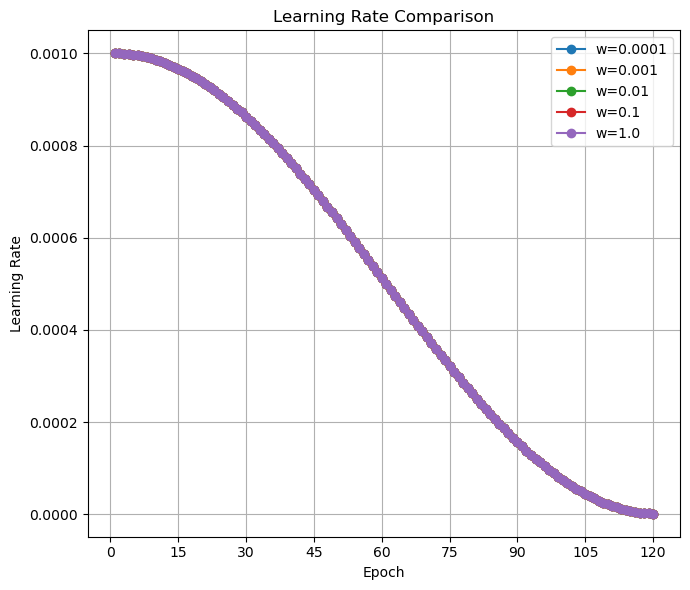

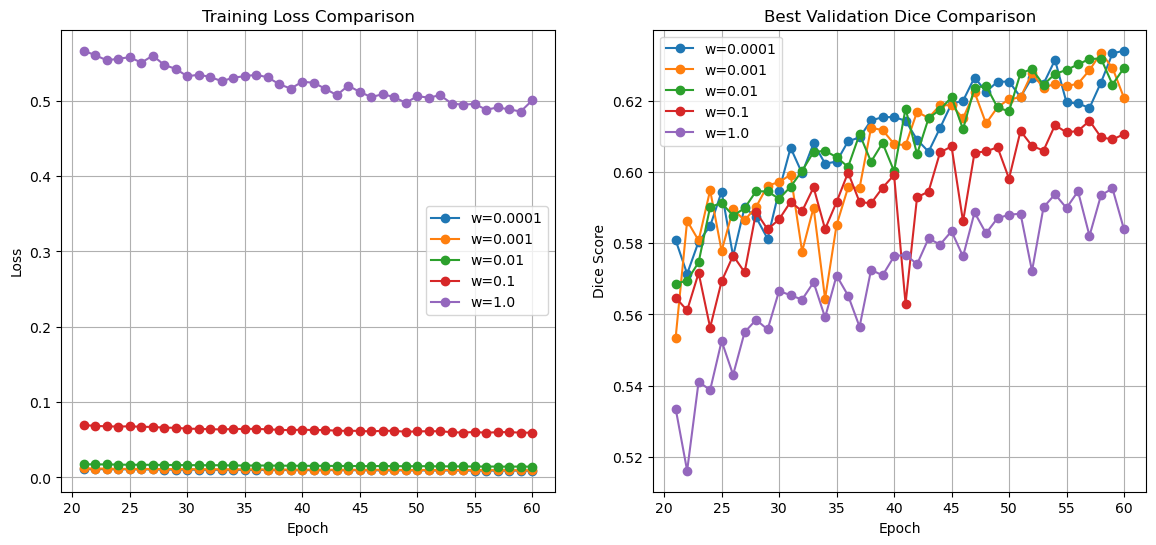

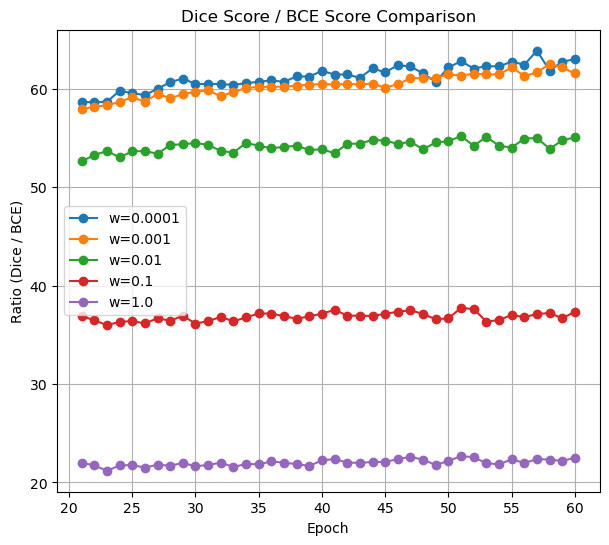

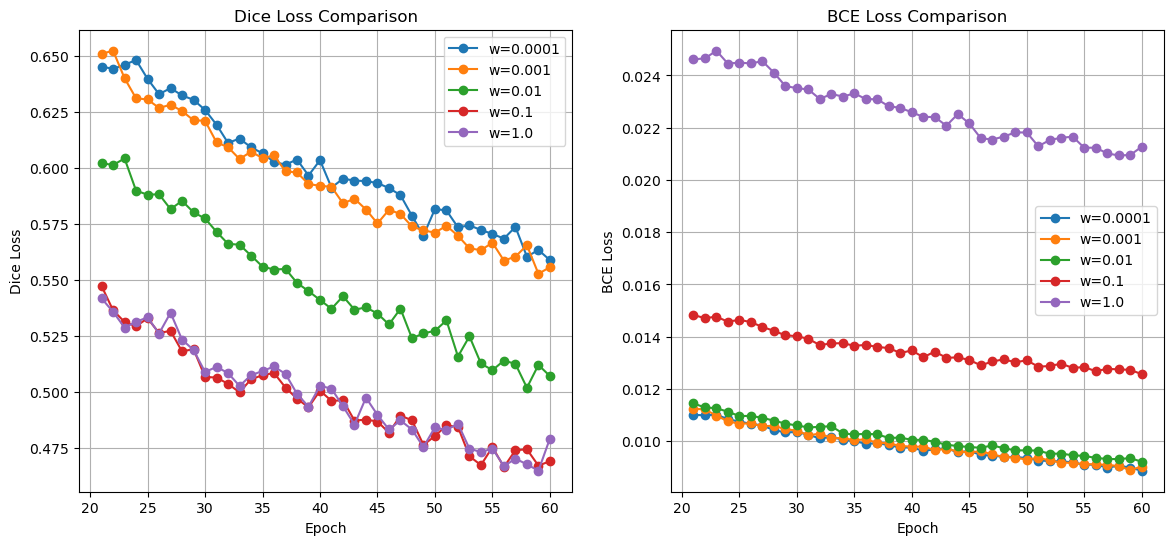

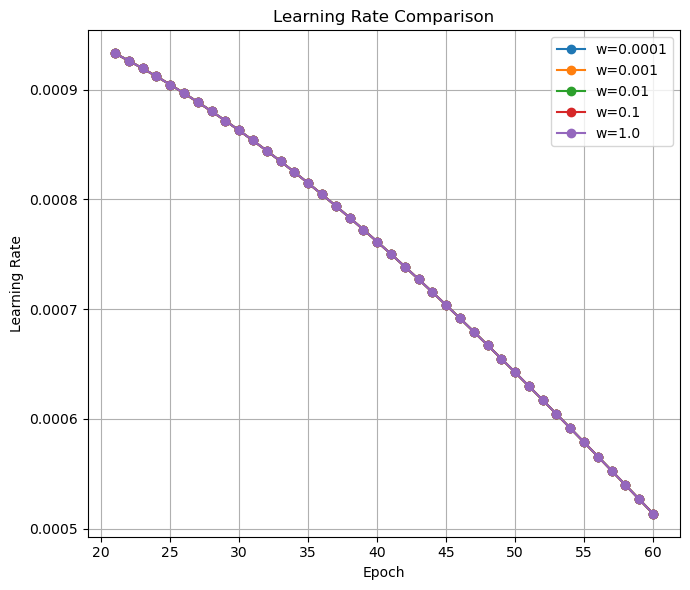

     Run  Initial Loss  Second Loss  Last Loss  Last - Initial  Last - Second  Last - Second Last
   w=1.0      0.984474     0.801485   0.443656       -0.540818      -0.357829            0.002712
   w=0.1      0.158409     0.109344   0.053514       -0.104894      -0.055830            0.000010
  w=0.01      0.082616     0.031947   0.012538       -0.070079      -0.019409            0.000109
w=0.0001      0.069238     0.022467   0.007743       -0.061495      -0.014724           -0.000034
 w=0.001      0.063899     0.022958   0.008223       -0.055676      -0.014735            0.000127


In [13]:
metrics_files = {
    "w=0.0001": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.0001_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full", "training_validation_metrics.csv"),
    "w=0.001": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.001_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full", "training_validation_metrics.csv"),
    "w=0.01": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.01_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full", "training_validation_metrics.csv"),
    "w=0.1": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.1_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full", "training_validation_metrics.csv"),
    #"weight_dice_0.2": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.2_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full", "training_validation_metrics.csv"),
    #"weight_dice_0.7": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.7_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full", "training_validation_metrics.csv"),
    "w=1.0": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce1.0_new_loss_cos_scheduler_more_augmented_adamw_more_epochs_full", "training_validation_metrics.csv"),
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))
fig3, (ax4, ax5) = plt.subplots(1, 2, figsize=(14, 6))
fig4, ax6 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Dice Score / BCE Score Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Ratio (Dice / BCE)")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Dice Loss Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Dice Loss")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

ax5.set_title("BCE Loss Comparison")
ax5.set_xlabel("Epoch")
ax5.set_ylabel("BCE Loss")
ax5.grid(True)
ax5.xaxis.set_major_locator(MaxNLocator(integer=True))

ax6.set_title("Learning Rate Comparison")
ax6.set_xlabel("Epoch")
ax6.set_ylabel("Learning Rate")
ax6.grid(True)
ax6.xaxis.set_major_locator(MaxNLocator(integer=True))


# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].tail(60)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)

    # Plot Dice/BCE Ratio
    ratio = epoch_summary["avg_loss_dice"] / epoch_summary["avg_loss_bce"]
    ax3.plot(epoch_summary["epoch"], ratio, marker='o', label=label)

    # Plot Dice Loss
    ax4.plot(epoch_summary["epoch"], epoch_summary["avg_loss_dice"], marker='o', label=label)
    ax5.plot(epoch_summary["epoch"], epoch_summary["avg_loss_bce"], marker='o', label=label)
    
    # Plot Learning Rate
    ax6.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
ax5.legend()
ax6.legend()
plt.tight_layout()
plt.show()

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))
fig3, (ax4, ax5) = plt.subplots(1, 2, figsize=(14, 6))
fig4, ax6 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Dice Score / BCE Score Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Ratio (Dice / BCE)")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Dice Loss Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Dice Loss")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

ax5.set_title("BCE Loss Comparison")
ax5.set_xlabel("Epoch")
ax5.set_ylabel("BCE Loss")
ax5.grid(True)
ax5.xaxis.set_major_locator(MaxNLocator(integer=True))

ax6.set_title("Learning Rate Comparison")
ax6.set_xlabel("Epoch")
ax6.set_ylabel("Learning Rate")
ax6.grid(True)
ax6.xaxis.set_major_locator(MaxNLocator(integer=True))


# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(120)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)

    # Plot Dice/BCE Ratio
    ratio = epoch_summary["avg_loss_dice"] / epoch_summary["avg_loss_bce"]
    ax3.plot(epoch_summary["epoch"], ratio, marker='o', label=label)

    # Plot Dice Loss
    ax4.plot(epoch_summary["epoch"], epoch_summary["avg_loss_dice"], marker='o', label=label)
    ax5.plot(epoch_summary["epoch"], epoch_summary["avg_loss_bce"], marker='o', label=label)
    
    # Plot Learning Rate
    ax6.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
ax5.legend()
ax6.legend()
plt.tight_layout()
plt.show()


fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))
fig3, (ax4, ax5) = plt.subplots(1, 2, figsize=(14, 6))
fig4, ax6 = plt.subplots(figsize=(7, 6))



ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Dice Score / BCE Score Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Ratio (Dice / BCE)")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Dice Loss Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Dice Loss")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

ax5.set_title("BCE Loss Comparison")
ax5.set_xlabel("Epoch")
ax5.set_ylabel("BCE Loss")
ax5.grid(True)
ax5.xaxis.set_major_locator(MaxNLocator(integer=True))

ax6.set_title("Learning Rate Comparison")
ax6.set_xlabel("Epoch")
ax6.set_ylabel("Learning Rate")
ax6.grid(True)
ax6.xaxis.set_major_locator(MaxNLocator(integer=True))


# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].iloc[20:60]
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)

    # Plot Dice/BCE Ratio
    ratio = epoch_summary["avg_loss_dice"] / epoch_summary["avg_loss_bce"]
    ax3.plot(epoch_summary["epoch"], ratio, marker='o', label=label)

    # Plot Dice Loss
    ax4.plot(epoch_summary["epoch"], epoch_summary["avg_loss_dice"], marker='o', label=label)
    ax5.plot(epoch_summary["epoch"], epoch_summary["avg_loss_bce"], marker='o', label=label)
    
    # Plot Learning Rate
    ax6.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
ax5.legend()
ax6.legend()
plt.tight_layout()
plt.show()


loss_summary = []

for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue

    df = pd.read_csv(filepath)

    # Keep one training loss per epoch (same value for all thresholds)
    epoch_loss = df.groupby("epoch", as_index=False)["avg_train_loss"].first()

    if len(epoch_loss) == 0:
        continue

    initial_loss = float(epoch_loss["avg_train_loss"].iloc[0])
    second_loss = float(epoch_loss["avg_train_loss"].iloc[1]) if len(epoch_loss) > 1 else initial_loss
    second_last_loss = float(epoch_loss["avg_train_loss"].iloc[-2]) if len(epoch_loss) > 1 else initial_loss
    last_loss = float(epoch_loss["avg_train_loss"].iloc[-1])

    initial_dice = float()

    loss_summary.append({
        "Run": label,
        "Initial Loss": initial_loss,
        "Second Loss": second_loss,
        "Last Loss": last_loss,
        "Last - Initial": last_loss - initial_loss,
        "Last - Second": last_loss - second_loss,
        "Last - Second Last": last_loss - second_last_loss
    })

loss_summary_df = pd.DataFrame(loss_summary)
loss_summary_df = loss_summary_df.sort_values(
    by=["Last - Initial", "Last - Second", "Last - Second Last"],
    ascending=[True, True, True]
).reset_index(drop=True)


print(loss_summary_df.to_string(index=False))

/tmp/ipykernel_2562573/2234694616.py:79: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend()
/tmp/ipykernel_2562573/2234694616.py:80: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax4.legend()
/tmp/ipykernel_2562573/2234694616.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax5.legend()


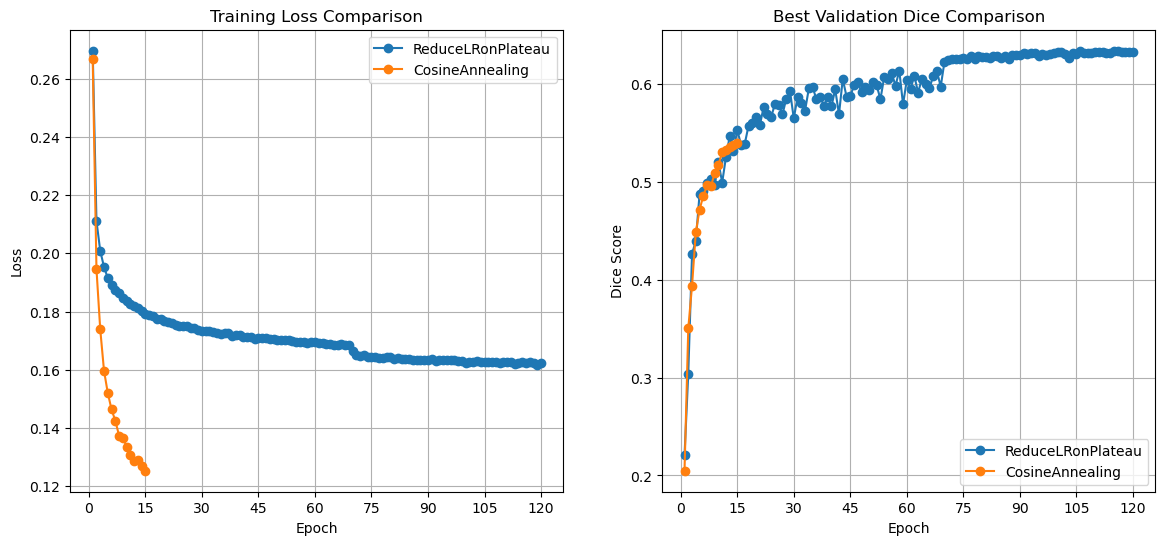

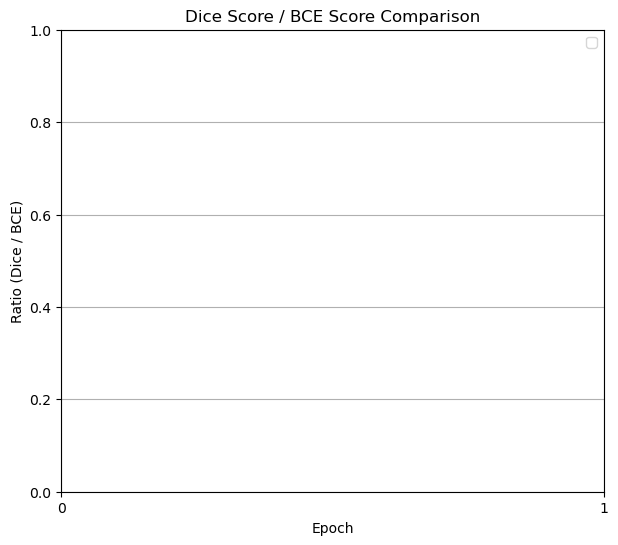

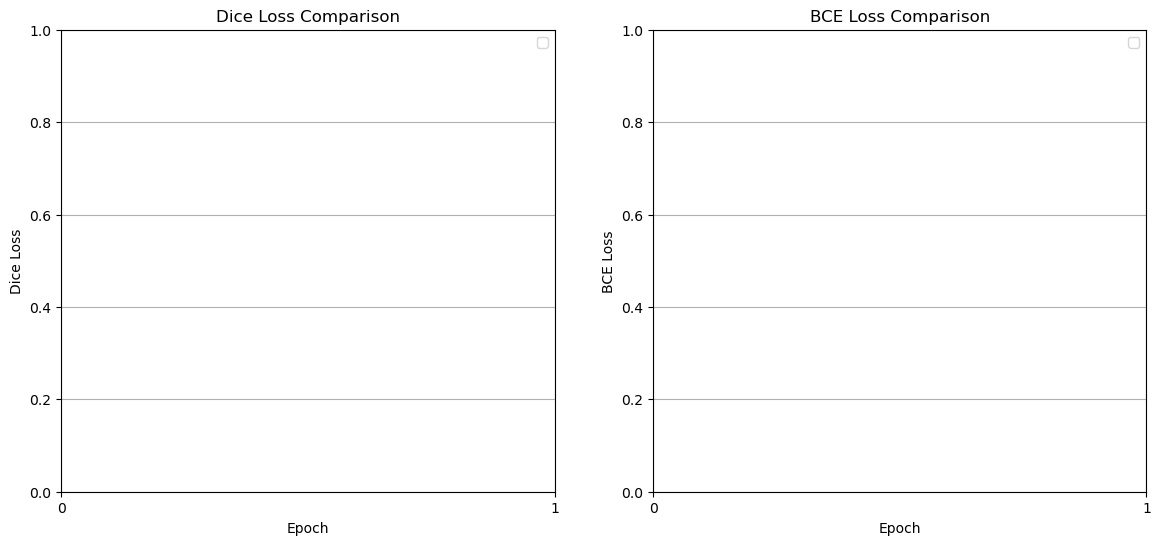

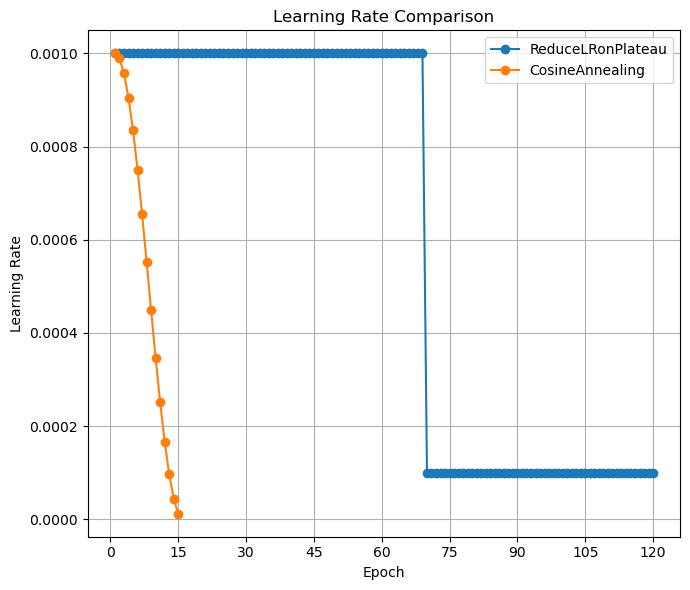

In [19]:
metrics_files = {
    "ReduceLRonPlateau": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.2_loss_scheduler_more_augmented_adamw_more_epochs/training_validation_metrics.csv"),
    "CosineAnnealing": os.path.join(OUTPUT_BASE_PATH, "model01_new_dicebce0.2_new_loss_cos_scheduler_more_augmented_adamw_more_epochs/training_validation_metrics.csv"),
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))
fig3, (ax4, ax5) = plt.subplots(1, 2, figsize=(14, 6))
fig4, ax6 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Dice Score / BCE Score Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Ratio (Dice / BCE)")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Dice Loss Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Dice Loss")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

ax5.set_title("BCE Loss Comparison")
ax5.set_xlabel("Epoch")
ax5.set_ylabel("BCE Loss")
ax5.grid(True)
ax5.xaxis.set_major_locator(MaxNLocator(integer=True))

ax6.set_title("Learning Rate Comparison")
ax6.set_xlabel("Epoch")
ax6.set_ylabel("Learning Rate")
ax6.grid(True)
ax6.xaxis.set_major_locator(MaxNLocator(integer=True))


# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx]
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)

    # Plot Dice/BCE Ratio
    #ratio = epoch_summary["avg_loss_dice"] / epoch_summary["avg_loss_bce"]
    #ax3.plot(epoch_summary["epoch"], ratio, marker='o', label=label)

    # Plot Dice Loss
    #ax4.plot(epoch_summary["epoch"], epoch_summary["avg_loss_dice"], marker='o', label=label)
    #ax5.plot(epoch_summary["epoch"], epoch_summary["avg_loss_bce"], marker='o', label=label)
    
    # Plot Learning Rate
    ax6.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
ax5.legend()
ax6.legend()
plt.tight_layout()
plt.show()


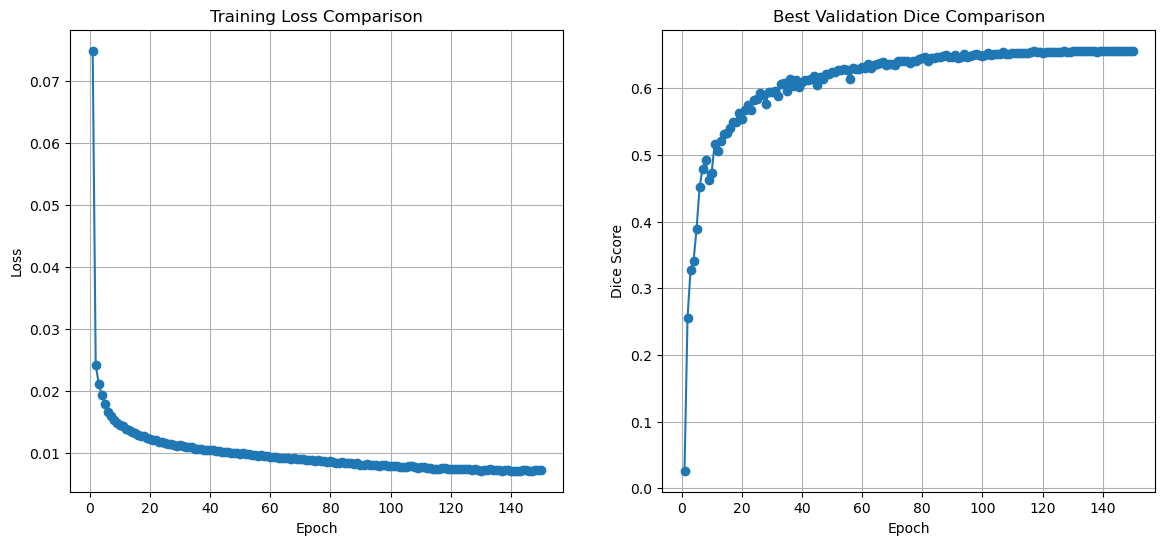

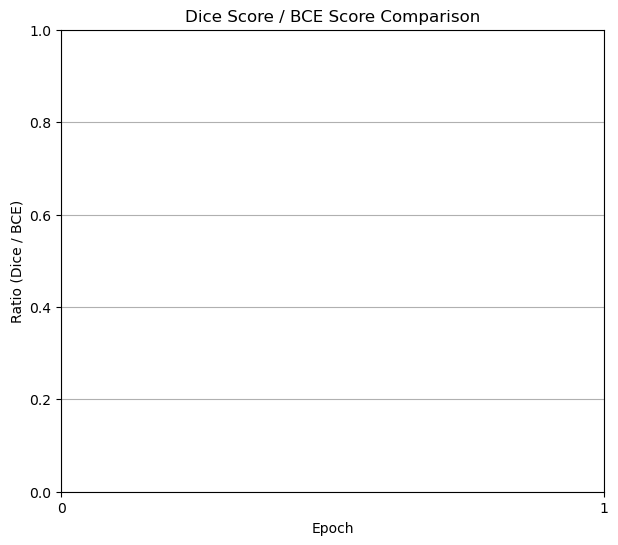

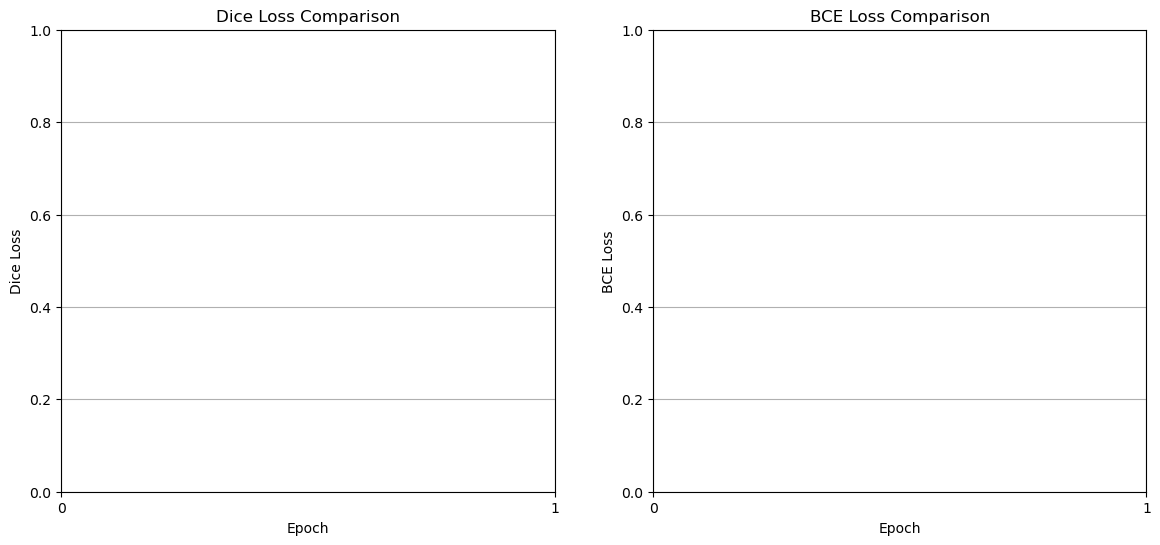

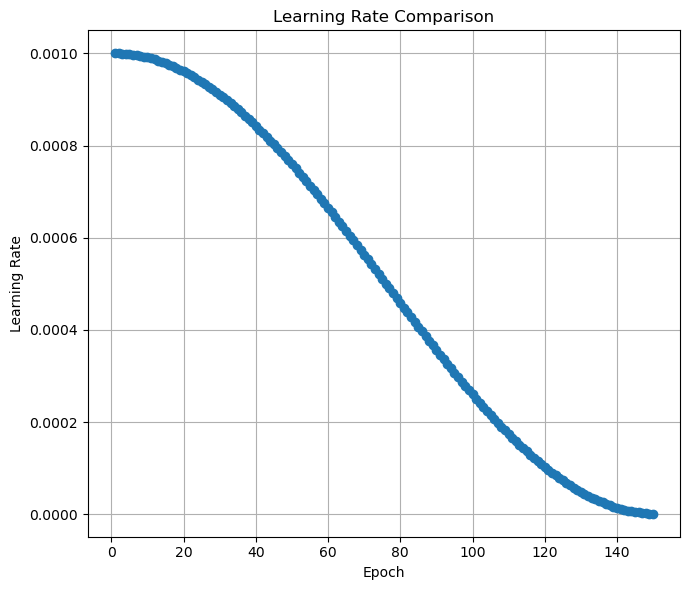

Best Epoch: 139.0, Best Dice: 0.6561102906844813, Best Threshold: 0.3


In [21]:
metrics_files = {
    "Final Submission": os.path.join(OUTPUT_BASE_PATH, "model01_kaggle_submission/training_validation_metrics.csv"),
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))
fig3, (ax4, ax5) = plt.subplots(1, 2, figsize=(14, 6))
fig4, ax6 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Dice Score / BCE Score Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Ratio (Dice / BCE)")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Dice Loss Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Dice Loss")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

ax5.set_title("BCE Loss Comparison")
ax5.set_xlabel("Epoch")
ax5.set_ylabel("BCE Loss")
ax5.grid(True)
ax5.xaxis.set_major_locator(MaxNLocator(integer=True))

ax6.set_title("Learning Rate Comparison")
ax6.set_xlabel("Epoch")
ax6.set_ylabel("Learning Rate")
ax6.grid(True)
ax6.xaxis.set_major_locator(MaxNLocator(integer=True))


# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx]
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)

    # Plot Dice/BCE Ratio
    #ratio = epoch_summary["avg_loss_dice"] / epoch_summary["avg_loss_bce"]
    #ax3.plot(epoch_summary["epoch"], ratio, marker='o', label=label)

    # Plot Dice Loss
    #ax4.plot(epoch_summary["epoch"], epoch_summary["avg_loss_dice"], marker='o', label=label)
    #ax5.plot(epoch_summary["epoch"], epoch_summary["avg_loss_bce"], marker='o', label=label)
    
    # Plot Learning Rate
    ax6.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)

# 4. Add legends and show

plt.tight_layout()
plt.show()

# Best Epoch 
best_epoch = epoch_summary.loc[epoch_summary["dice"].idxmax()]
print(f"Best Epoch: {best_epoch['epoch']}, Best Dice: {best_epoch['dice']}, Best Threshold: {best_epoch['threshold']}")